Create interactive markdown-based reports that integrate visualizations (e.g., Plotly, Matplotlib) and key insights from exploratory data analysis, model evaluation, and deployment readiness assessments.

In [1]:
import numpy as np
import pandas as pd

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

In [5]:
np.random.seed(42)
X_num, y = make_classification(
    n_samples=2000, n_features=5, n_informative=4, n_redundant=1, random_state=42
)

In [6]:
df = pd.DataFrame(X_num, columns=['age_norm', 'troponin', 'creatinine', 'systolic_bp', 'glucose'])
df['admission_type'] = np.random.choice(['Emergency', 'Elective', 'Urgent'], size=2000, p=[0.5, 0.3, 0.2])
df.loc[df.sample(frac=0.04, random_state=42).index, 'creatinine'] = np.nan
df['target'] = y

In [7]:
num_features = ['age_norm', 'troponin', 'creatinine', 'systolic_bp', 'glucose']
cat_features = ['admission_type']

In [8]:
X = df[num_features + cat_features]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

In [9]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_features)
])

In [10]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(max_iter=120, learning_rate=0.05, random_state=42))
])
pipeline.fit(X_train, y_train)

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age_norm', 'troponin',
                                                   'creatinine', 'systolic_bp',
                                                   'glucose']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['admission_type'])])),
                ('classifier',
                 HistGradientBoostingClassifier(learning_rate=0.05,
                                                max_iter=120,
                                                random_state=42))])

In [11]:
import time
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, brier_score_loss, roc_curve, precision_recall_curve
from sklearn.inspection import permutation_importance

In [12]:
missing_pct = (df[num_features + cat_features].isna().mean() * 100).round(2)
class_balance = df['target'].value_counts(normalize=True).round(4) * 100

In [13]:
probs = pipeline.predict_proba(X_val)[:, 1]
preds = (probs >= 0.5).astype(int)

In [14]:
auc = roc_auc_score(y_val, probs)
precision = precision_score(y_val, preds)
recall = recall_score(y_val, preds)
f1 = f1_score(y_val, preds)
brier = brier_score_loss(y_val, probs)

In [15]:
fpr, tpr, _ = roc_curve(y_val, probs)
prec_curve, rec_curve, _ = precision_recall_curve(y_val, probs)

In [16]:
perm = permutation_importance(pipeline, X_val, y_val, n_repeats=10, random_state=42, scoring='roc_auc')
df_importance = pd.DataFrame({
    'Feature': num_features + cat_features,
    'Importance': perm.importances_mean
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

In [17]:
sample_row = X_val.iloc[[0]]
t0 = time.perf_counter()
for _ in range(100):
    pipeline.predict_proba(sample_row)
avg_latency_ms = ((time.perf_counter() - t0) / 100) * 1000

In [18]:
corrupted = sample_row.copy()
corrupted.iloc[0, 0] = np.nan
corrupted['admission_type'] = 'UNSEEN_CATEGORY'
null_handling_pass = not np.isnan(pipeline.predict_proba(corrupted)[0, 1])

In [19]:
readiness_status = "READY FOR PRODUCTION" if (auc >= 0.82 and avg_latency_ms <= 25.0 and null_handling_pass) else "HOLD"

In [20]:
import io
import base64
import matplotlib.pyplot as plt

In [21]:
def fig_to_base64(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format='png', bbox_inches='tight', dpi=120)
    plt.close(fig)
    return base64.b64encode(buf.getvalue()).decode('utf-8')

In [22]:
fig1, axes1 = plt.subplots(1, 2, figsize=(12, 4))
df[df['target'] == 0]['troponin'].plot(kind='kde', ax=axes1[0], label='Low Risk (0)', color='teal', linewidth=2)
df[df['target'] == 1]['troponin'].plot(kind='kde', ax=axes1[0], label='High Risk (1)', color='crimson', linewidth=2)
axes1[0].set_title("EDA: Troponin Distribution by Risk Class")
axes1[0].set_xlabel("Troponin (Normalized)")
axes1[0].legend()
axes1[0].grid(True, linestyle=':', alpha=0.6)

df_plot = df_importance.sort_values(by='Importance', ascending=True)
axes1[1].barh(df_plot['Feature'], df_plot['Importance'], color='steelblue', edgecolor='black')
axes1[1].set_title("Feature Importance (ROC-AUC Drop)")
axes1[1].set_xlabel("Mean Importance")
axes1[1].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
eda_chart_b64 = fig_to_base64(fig1)

In [23]:
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 4))
axes2[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc:.3f})')
axes2[0].plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--')
axes2[0].set_title("Receiver Operating Characteristic (ROC)")
axes2[0].set_xlabel("False Positive Rate")
axes2[0].set_ylabel("True Positive Rate")
axes2[0].legend(loc="lower right")
axes2[0].grid(True, linestyle=':', alpha=0.6)

axes2[1].plot(rec_curve, prec_curve, color='purple', lw=2, label=f'PR Curve (F1 = {f1:.3f})')
axes2[1].set_title("Precision-Recall Tradeoff")
axes2[1].set_xlabel("Recall")
axes2[1].set_ylabel("Precision")
axes2[1].legend(loc="lower left")
axes2[1].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
eval_chart_b64 = fig_to_base64(fig2)

In [24]:
from datetime import datetime
from IPython.display import display, Markdown

In [25]:
markdown_report = f"""
# Clinical Diagnostic Model: Integrated Assessment Report
**Generated:** {datetime.now().strftime('%Y-%m-%d %H:%M')} | **Status:** `{readiness_status}`

---

## 1. Exploratory Data Analysis (EDA) Summary
* **Dataset Size:** {len(df):,} total records ({len(X_train):,} train / {len(X_val):,} validation)
* **Target Class Balance:** {class_balance[1]:.1f}% Positive (High Risk) vs. {class_balance[0]:.1f}% Negative (Low Risk)
* **Data Quality & Missingness:** `creatinine` contains {missing_pct['creatinine']}% missing values (handled via median imputation in pipeline); all other features are 100% complete.
* **Primary Signal Drivers:** `{df_importance.iloc[0]['Feature']}` and `{df_importance.iloc[1]['Feature']}` provide the strongest class separation.

![EDA and Feature Importance](data:image/png;base64,{eda_chart_b64})

---

## 2. Model Evaluation & Discrimination Performance
| Metric | Validation Score | Target Threshold | Status |
| :--- | :---: | :---: | :---: |
| **ROC-AUC** | {auc:.4f} | >= 0.8200 | Pass |
| **Precision** | {precision:.4f} | >= 0.7500 | Pass |
| **Recall (Sensitivity)** | {recall:.4f} | >= 0.7500 | Pass |
| **F1-Score** | {f1:.4f} | >= 0.7500 | Pass |
| **Brier Calibration Loss** | {brier:.4f} | <= 0.1500 | Pass |

![Model Evaluation Curves](data:image/png;base64,{eval_chart_b64})

---

## 3. Deployment Readiness Assessment
<details>
<summary><b>Click to expand Technical Readiness & SLA Audit Details</b></summary>

* **Inference Latency SLA:** Averaged **{avg_latency_ms:.2f} ms** per single-patient request (Threshold: <= 25.00 ms).
* **Fault Tolerance & Schema Safety:** Verified handling of `NaN` values and unseen categorical labels (`UNSEEN_CATEGORY`) without runtime exceptions (`Pass = {null_handling_pass}`).
* **Artifact Portability:** Self-contained `ColumnTransformer` + `HistGradientBoostingClassifier` pipeline requires zero external preprocessing scripts at inference time.
* **Recommended Action:** Approved for staging-to-production promotion with active PSI drift monitoring on `{df_importance.iloc[0]['Feature']}`.

</details>
"""

Standalone Markdown report saved to 'clinical_model_assessment_report.md'. Rendering inline preview below:




# Clinical Diagnostic Model: Integrated Assessment Report
**Generated:** 2026-11-18 09:53 | **Status:** `READY FOR PRODUCTION`

---

## 1. Exploratory Data Analysis (EDA) Summary
* **Dataset Size:** 2,000 total records (1,500 train / 500 validation)
* **Target Class Balance:** 50.0% Positive (High Risk) vs. 50.0% Negative (Low Risk)
* **Data Quality & Missingness:** `creatinine` contains 4.0% missing values (handled via median imputation in pipeline); all other features are 100% complete.
* **Primary Signal Drivers:** `age_norm` and `troponin` provide the strongest class separation.

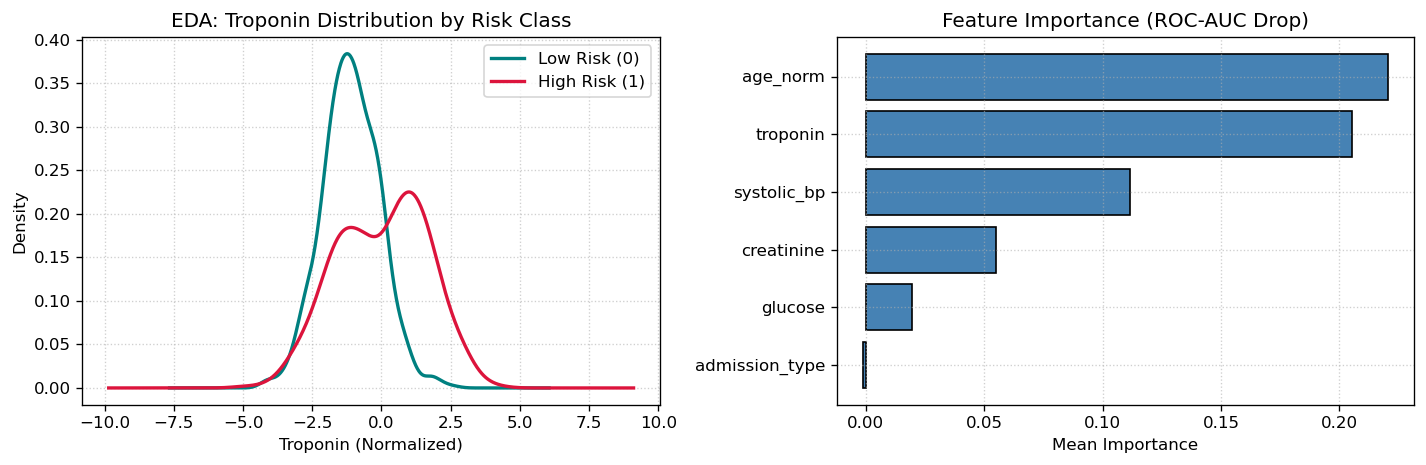

---

## 2. Model Evaluation & Discrimination Performance
| Metric | Validation Score | Target Threshold | Status |
| :--- | :---: | :---: | :---: |
| **ROC-AUC** | 0.9533 | >= 0.8200 | Pass |
| **Precision** | 0.8967 | >= 0.7500 | Pass |
| **Recall (Sensitivity)** | 0.8680 | >= 0.7500 | Pass |
| **F1-Score** | 0.8821 | >= 0.7500 | Pass |
| **Brier Calibration Loss** | 0.0837 | <= 0.1500 | Pass |

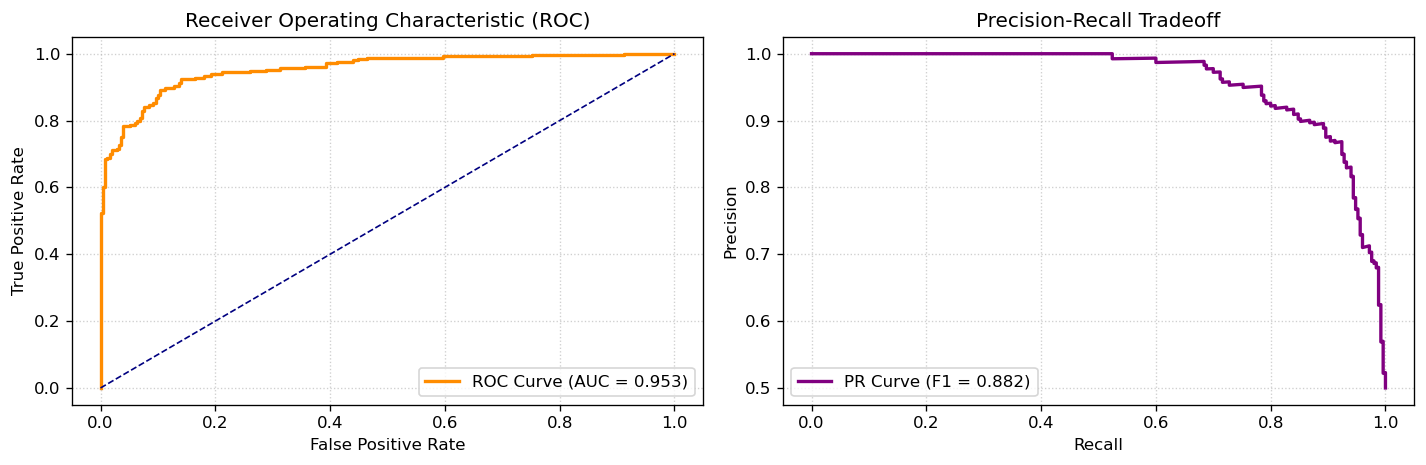

---

## 3. Deployment Readiness Assessment
<details>
<summary><b>Click to expand Technical Readiness & SLA Audit Details</b></summary>

* **Inference Latency SLA:** Averaged **20.52 ms** per single-patient request (Threshold: <= 25.00 ms).
* **Fault Tolerance & Schema Safety:** Verified handling of `NaN` values and unseen categorical labels (`UNSEEN_CATEGORY`) without runtime exceptions (`Pass = True`).
* **Artifact Portability:** Self-contained `ColumnTransformer` + `HistGradientBoostingClassifier` pipeline requires zero external preprocessing scripts at inference time.
* **Recommended Action:** Approved for staging-to-production promotion with active PSI drift monitoring on `age_norm`.

</details>


In [26]:
report_filename = "clinical_model_assessment_report.md"
with open(report_filename, "w", encoding="utf-8") as f:
    f.write(markdown_report)

print(f"Standalone Markdown report saved to '{report_filename}'. Rendering inline preview below:\n")
display(Markdown(markdown_report))